In [1]:
import pandas as pd

orders = pd.read_csv('/content/olist_orders_dataset.csv')
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [2]:
orders.shape
print(orders.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
None


Converting date_cols into datetime64

In [3]:
date_cols = ['order_purchase_timestamp', 'order_approved_at',
             'order_delivered_carrier_date', 'order_delivered_customer_date',
             'order_estimated_delivery_date']

for col in date_cols:
  orders[col] = pd.to_datetime(orders[col])

orders.dtypes

,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


Checking missing values

In [4]:
orders[orders['order_delivered_customer_date'].isnull()]['order_status'].value_counts()

,count
order_status,
shipped,1107
canceled,619
unavailable,609
invoiced,314
processing,301
delivered,8
created,5
approved,2


Making a new variable that does not have missing values

In [5]:
delivered = orders[orders['order_delivered_customer_date'].notnull()].copy()

In [6]:
delivered[['order_approved_at', 'order_delivered_carrier_date']].isnull().sum()

,0
order_approved_at,14
order_delivered_carrier_date,1


In [7]:
before = len(delivered)
delivered = delivered.dropna(subset=['order_delivered_carrier_date', 'order_approved_at']).copy()
print(before, len(delivered), before - len(delivered))

96476 96461 15


Creating a 'is_late' col

In [8]:
delivered['is_late'] = delivered['order_delivered_customer_date'] > delivered['order_estimated_delivery_date']

In [9]:
delivered['is_late'].value_counts()

,count
is_late,
False,88635
True,7826


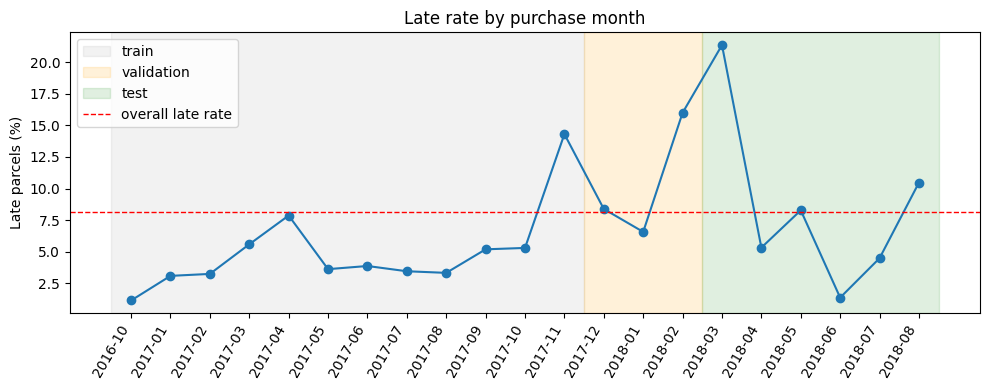

In [131]:
import matplotlib.pyplot as plt

monthly = delivered.groupby('year_month')['is_late'].agg(['size', 'mean'])
monthly = monthly[monthly['size'] >= 200]
labels = [str(m) for m in monthly.index]
x = range(len(labels))

i_val = labels.index('2017-12')
i_test = labels.index('2018-03')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, monthly['mean'] * 100, marker='o', color='#1f77b4')
ax.axvspan(-0.5, i_val - 0.5, color='grey', alpha=0.10, label='train')
ax.axvspan(i_val - 0.5, i_test - 0.5, color='orange', alpha=0.15, label='validation')
ax.axvspan(i_test - 0.5, len(labels) - 0.5, color='green', alpha=0.12, label='test')
ax.axhline(delivered['is_late'].mean() * 100, color='red', linestyle='--', linewidth=1,
           label='overall late rate')

ax.set_xticks(list(x))
ax.set_xticklabels(labels, rotation=60, ha='right')
ax.set_ylabel('Late parcels (%)')
ax.set_title('Late rate by purchase month')
ax.legend(loc='upper left')
plt.tight_layout()
fig.savefig('/content/late_rate_by_month.png', dpi=150, bbox_inches='tight')
plt.show()

Checkin for unwanted delievery dates

In [10]:
# counting the orders where customer received parcel before even ordering
(delivered['order_delivered_customer_date']< delivered['order_purchase_timestamp']).sum()

np.int64(0)

In [11]:
# counting the orders where the delievery guy pickup order after customer already have delievery
(delivered['order_delivered_carrier_date']> delivered['order_delivered_customer_date']).sum()

np.int64(23)

In [12]:
# counting orders where delievery guy pickup before customer purchase
(delivered['order_delivered_carrier_date']< delivered['order_purchase_timestamp']).sum()

np.int64(165)

In [13]:
# droping this impossible rows
before = len(delivered)

delivered = delivered.drop(delivered[delivered['order_delivered_carrier_date'] > delivered['order_delivered_customer_date']].index)
delivered = delivered.drop(delivered[delivered['order_delivered_carrier_date']< delivered['order_purchase_timestamp']].index)
print(before,len(delivered))

96461 96273


Checking for duplicate orders

In [14]:
delivered['order_id'].duplicated().sum()

np.int64(0)

Loading another file.

In [15]:
items = pd.read_csv('/content/olist_order_items_dataset.csv')
print(items.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB
None


In [16]:
items['order_id'].value_counts()

,count
order_id,
8272b63d03f5f79c56e9e4120aec44ef,21
1b15974a0141d54e36626dca3fdc731a,20
ab14fdcfbe524636d65ee38360e22ce8,20
9ef13efd6949e4573a18964dd1bbe7f5,15
428a2f660dc84138d969ccd69a0ab6d5,15
...,...
5a082b558a3798d3e36d93bfa8ca1eae,1
5a07264682e0b8fbb3f166edbbffc6e8,1
5a071192a28951b76774e5a760c8c9b7,1


Merging the items table so we have one row per order

In [17]:
g = items.groupby('order_id')

n_items = g['order_item_id'].count()
n_sellers = g['seller_id'].nunique()
seller_id = g['seller_id'].first()
price = g['price'].sum()
freight = g['freight_value'].sum()

items_agg = pd.DataFrame({
    'n_items': n_items,
    'n_sellers': n_sellers,
    'seller_id': seller_id,
    'price': price,
    'freight': freight
}).reset_index()

items_agg.shape

(98666, 6)

In [18]:
before = len(delivered)
delivered = delivered.merge(items_agg, on='order_id', how='left')
print(before, len(delivered))

96273 96273


Loading another file for finding products info(weight, size)

In [19]:
products = pd.read_csv('/content/olist_products_dataset.csv')
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [20]:
# Checking for null values in products table
products.isnull().sum()

,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [21]:
# Checking for values = 0 in weight col
(products['product_weight_g'] == 0).sum()

np.int64(4)

In [22]:
# converting 0 into null for weight col
products.loc[products['product_weight_g'] == 0, 'product_weight_g'] = None
products['product_weight_g'].isnull().sum()

np.int64(6)

In [23]:
# Checking for missing values in len, height, width
(products[['product_length_cm', 'product_height_cm', 'product_width_cm']] == 0).sum()

,0
product_length_cm,0
product_height_cm,0
product_width_cm,0


In [24]:
# Filling the missing categories
products['product_category_name'] = products['product_category_name'].fillna('unknown')
products['product_category_name'].isnull().sum()

np.int64(0)

In [25]:
# Keeping only the cols we need to use in delievred table.
products = products[['product_id', 'product_category_name', 'product_weight_g',
                     'product_length_cm', 'product_height_cm', 'product_width_cm']]
products.shape

(32951, 6)

In [26]:
# Making temporary table
items_prod = items.merge(products, on= 'product_id', how= 'left')
items_prod.shape

(112650, 12)

In [27]:
items_prod['volume_cm3'] = (items_prod['product_length_cm'] *
                            items_prod['product_height_cm'] *
                            items_prod['product_width_cm'])

In [28]:
# Squashing it to one row per order
g = items_prod.groupby('order_id')

weight_g = g['product_weight_g'].sum(min_count=1)
volume_cm3 = g['volume_cm3'].sum(min_count=1)
category = g['product_category_name'].first()

prod_agg = pd.DataFrame({
    'weight_g': weight_g,
    'volume_cm3': volume_cm3,
    'category': category
}).reset_index()

prod_agg.shape

(98666, 4)

In [29]:
before = len(delivered)
delivered = delivered.merge(prod_agg, on='order_id', how='left')
print(before, len(delivered))

96273 96273


In [30]:
# Checking for missing values
delivered[['weight_g', 'volume_cm3', 'category']].isnull().sum()

,0
weight_g,22
volume_cm3,16
category,0


In [31]:
# filling it with median
delivered['weight_g'] = delivered['weight_g'].fillna(delivered['weight_g'].median())
delivered['volume_cm3'] = delivered['volume_cm3'].fillna(delivered['volume_cm3'].median())

delivered[['weight_g', 'volume_cm3', 'category']].isnull().sum()

,0
weight_g,0
volume_cm3,0
category,0


Loading new file to get sellers info

In [32]:
sellers = pd.read_csv('/content/olist_sellers_dataset.csv')
sellers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   seller_id               3095 non-null   object
 1   seller_zip_code_prefix  3095 non-null   int64 
 2   seller_city             3095 non-null   object
 3   seller_state            3095 non-null   object
dtypes: int64(1), object(3)
memory usage: 96.8+ KB


In [33]:
# Checking for duplicate and missing values
print(sellers["seller_id"].duplicated().sum())

# Checking for empty cells in cols
print(sellers.isnull().sum())

0
seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64


In [34]:
sellers = sellers[['seller_id', 'seller_zip_code_prefix', 'seller_state']]

# merging in the main table
before = len(delivered)
delivered = delivered.merge(sellers, on='seller_id', how='left')
print(before, len(delivered))

96273 96273


Loading new file to get customer info

In [35]:
customers = pd.read_csv('/content/olist_customers_dataset.csv')
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


In [36]:
# Checking for duplicate and missing values
print(customers['customer_id'].duplicated().sum())

# Checking for empty cells in cols
print(customers.isnull().sum())

0
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64


In [37]:
customers = customers[['customer_id', 'customer_zip_code_prefix', 'customer_state']]

# merging them into main delivered table
before = len(delivered)
delivered = delivered.merge(customers, on='customer_id', how='left')
print(before, len(delivered))


96273 96273


Loading new file to get info about geo location of sellers and customers

In [38]:
geo = pd.read_csv('/content/olist_geolocation_dataset.csv')
geo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  object 
 4   geolocation_state            1000163 non-null  object 
dtypes: float64(2), int64(1), object(2)
memory usage: 38.2+ MB


In [39]:
# Checking total no. of unique zip codes
geo['geolocation_zip_code_prefix'].nunique()

19015

In [40]:
geo_agg = geo.groupby('geolocation_zip_code_prefix').agg(
    lat=('geolocation_lat', 'mean'),
    lng=('geolocation_lng', 'mean')
).reset_index()

geo_agg.shape

(19015, 3)

In [41]:
# Dividing geo location into two parts 'seller' and 'customer'
seller_geo = geo_agg.rename(columns={
    'geolocation_zip_code_prefix': 'seller_zip_code_prefix',
    'lat': 'seller_lat',
    'lng': 'seller_lng'
})

# Merging it into delivered table
before = len(delivered)
delivered = delivered.merge(seller_geo, on='seller_zip_code_prefix', how='left')
print(before, len(delivered))

customer_geo = geo_agg.rename(columns={
    'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
    'lat': 'customer_lat',
    'lng': 'customer_lng'
})

before = len(delivered)
delivered = delivered.merge(customer_geo, on='customer_zip_code_prefix', how='left')
print(before, len(delivered))

96273 96273
96273 96273


In [42]:
# Checking missing values
delivered[['seller_lat', 'seller_lng', 'customer_lat', 'customer_lng']].isnull().sum()

,0
seller_lat,215
seller_lng,215
customer_lat,264
customer_lng,264


# Using 'haversine' formula to find distance.
 Haversine formula: straight-line distance (km) between two lat/lng points,
 taking the curve of the earth into account.

In [43]:
import numpy as np

# formula works in radians, so converting degrees to radians
lat1 = np.radians(delivered['seller_lat'])
lng1 = np.radians(delivered['seller_lng'])
lat2 = np.radians(delivered['customer_lat'])
lng2 = np.radians(delivered['customer_lng'])

# 'a' = squared half-chord length between the two points
a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2)**2

# convert to distance. 6371 = earth's radius in km
# Missing lat/lng gives NaN distance, which we handle later
delivered['distance_km'] = 6371 * 2 * np.arcsin(np.sqrt(a))

delivered['distance_km'].describe()

,distance_km
count,95795.000000
mean,600.644405
std,593.689482
min,0.000000
25%,185.670538
50%,433.676817
75%,798.310959
max,8677.911622


In [44]:
# max value is around 8000 whereas the longest dist in the country is around 4500 so its an error
(delivered['distance_km'] > 4500).sum()
# o/p was np.int(4)

# converting them into "None"
delivered.loc[delivered['distance_km'] > 4500, 'distance_km'] = None

print(delivered['distance_km'].describe())

count    95791.000000
mean       600.417409
std        592.578019
min          0.000000
25%        185.652914
50%        433.645282
75%        798.282592
max       3927.406027
Name: distance_km, dtype: float64


In [45]:
# checking for missing values.
delivered['distance_km'].isnull().sum()

np.int64(482)

In [46]:
# Making flag to keep track of those places which are null and to be filled by median later
delivered['distance_missing'] = delivered['distance_km'].isnull()

# filling with median
delivered['distance_km'] = delivered['distance_km'].fillna(delivered['distance_km'].median())

delivered['distance_km'].isnull().sum()

np.int64(0)

### Saving the new cleaned dataset into csv file  

In [47]:
delivered.to_csv('/content/orders_model.csv', index=False)
delivered.shape

(96273, 27)

In [48]:
# Used to convert date cols into datetime64.

# pd.read_csv('orders_model.csv', parse_dates=['order_purchase_timestamp', 'order_delivered_carrier_date',
                                              # 'order_delivered_customer_date', 'order_estimated_delivery_date'])

### Creating features from dates

Models need numbers, not dates, so I turned the date columns into numbers.
Every feature uses only information known when the carrier picks up the
parcel, so none of them leak the delivery outcome.

- promised_days: days between purchase and the promised delivery date.
  A longer promise gives more room, so late delivery is less likely.
- handoff_days: days between purchase and carrier pickup. A slow handoff
  by the seller makes a late delivery more likely.
- purchase_month: month of purchase (1-12). Busy months such as Black
  Friday may have more delays.
- purchase_dow: day of week of purchase (0 = Monday, 6 = Sunday).
  Weekend orders may be handled differently.

In [49]:
# adding a new feature into table
delivered['promised_days'] = (delivered['order_estimated_delivery_date'] - delivered['order_purchase_timestamp']).dt.days

delivered['promised_days'].describe()

,promised_days
count,96273.000000
mean,23.373625
std,8.754876
min,2.000000
25%,18.000000
50%,23.000000
75%,28.000000
max,155.000000


In [50]:
delivered['handoff_days'] = (delivered['order_delivered_carrier_date'] - delivered['order_purchase_timestamp']).dt.total_seconds() / 86400

delivered['purchase_month'] = delivered['order_purchase_timestamp'].dt.month

delivered['purchase_dow'] = delivered['order_purchase_timestamp'].dt.dayofweek

delivered[['handoff_days', 'purchase_month', 'purchase_dow']].describe()

,handoff_days,purchase_month,purchase_dow
count,96273.000000,96273.000000,96273.000000
mean,3.233278,6.030839,2.757222
std,3.552186,3.230851,1.967749
min,0.000370,1.000000,0.000000
25%,1.130266,3.000000,1.000000
50%,2.204606,6.000000,3.000000
75%,4.069572,8.000000,4.000000
max,125.775521,12.000000,6.000000


In [51]:
# date range of parcel (oldest, newest)
delivered['order_purchase_timestamp'].min(), delivered['order_purchase_timestamp'].max()

(Timestamp('2016-09-15 12:16:38'), Timestamp('2018-08-29 15:00:37'))

In [52]:
delivered['year_month'] = delivered['order_purchase_timestamp'].dt.to_period('M')

delivered.groupby('year_month').agg(
    orders=('order_id', 'count'),
    late_rate=('is_late', 'mean')
)

,orders,late_rate
year_month,,
2016-09,1,1.000000
2016-10,266,0.011278
2016-12,1,0.000000
2017-01,747,0.030790
2017-02,1639,0.032337
2017-03,2545,0.055796
2017-04,2303,0.078593
2017-05,3544,0.036117
2017-06,3134,0.038609


We are using "time split" instead of "random split" because a random split would let the model see the same period
as the test orders.

In [53]:
cutoff = pd.Timestamp('2018-03-01')

train = delivered[delivered['order_purchase_timestamp']< cutoff].copy()
test = delivered[delivered['order_purchase_timestamp']>= cutoff].copy()

print(len(train), len(test))
print(train['is_late'].mean(), test['is_late'].mean())

57285 38988
0.07670419830671206 0.08795013850415513


## Creating one baseline model with limited features.

In [54]:
features = ['promised_days', 'handoff_days', 'distance_km',
            'weight_g', 'freight', 'price', 'n_items', 'volume_cm3',
             'purchase_month', 'purchase_dow', 'distance_missing']

x_train = train[features]
y_train = train['is_late']

x_test = test[features]
y_test = test['is_late']

print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)


(57285, 11) (57285,) (38988, 11) (38988,)


Using "LogisticRegression" as baseline model

In [55]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(x_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [56]:
y_pred = model.predict_proba(x_test)[:, 1]
y_pred[:5]

array([0.09554565, 0.02691871, 0.01469538, 0.08004954, 0.0608846 ])

In [57]:
# using metric score to understand model auc and precision

from sklearn.metrics import roc_auc_score, average_precision_score

roc_auc = roc_auc_score(y_test, y_pred)
pr_soc = average_precision_score(y_test, y_pred)

print('roc_auc :', roc_auc)
print('pr_soc :', pr_soc)
print('Random guess :',y_test.mean())

roc_auc : 0.7426960385259922
pr_soc : 0.3091277770945112
Random guess : 0.08795013850415513


### Precision @ K and Recall @ K

Operations can only act on a limited number of parcels per day, so a model is only useful if its top picks are right. hence we flag the 'K' parcels with the highest predicted late probability and measure:

- Precision@K: of the K flagged parcels, the share that were truly late.
- Recall@K: of all late parcels, the share caught within the K flagged.

In [58]:
import numpy as np

K = 1000

top_k = np.argsort(y_pred)[::-1][:K]

precision_at_k = y_test.values[top_k].mean()
recall_at_k = y_test.values[top_k].sum() / y_test.sum()

print('Precision @ K:', precision_at_k)
print('Recall @ K:', recall_at_k)

Precision @ K: 0.534
Recall @ K: 0.1557305336832896


In [59]:
# Saving the baseline model result so that we can compare it with our best fit model results.

baseline_results = {
    'PR-SOC': 0.3091,
    'ROC-AUC': 0.7427,
    'Precision@1000': 0.534,
    'Recall@1000': 0.1557
}

baseline_results

{'PR-SOC': 0.3091,
 'ROC-AUC': 0.7427,
 'Precision@1000': 0.534,
 'Recall@1000': 0.1557}

### Picking the right features for training our final model !!

In [60]:
delivered.dtypes

,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,datetime64[ns]
order_approved_at,datetime64[ns]
order_delivered_carrier_date,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]
is_late,bool
n_items,int64


### Leakage table: what is allowed at carrier pickup

Prediction moment: when the carrier picks up the parcel.

Leak (excluded): 'order_delivered_customer_date' (the actual delivery date),
and 'is_late' itself (the label).

Identifiers and constants (excluded): 'order_id', 'customer_id', 'order_status'.

Raw dates (excluded): turned into 'promised_days', 'handoff_days',
'purchase_month' and 'purchase_dow' instead.

Zip prefixes (excluded): they are codes, not real numbers.

Allowed, new in this step: 'n_sellers', 'category', 'seller_state',
'customer_state', 'seller and customer lat/lng'.

Later: 'seller_id' as a past late rate computed from earlier data only.

In [61]:
delivered[['category', 'seller_state', 'customer_state']].nunique()

,0
category,74
seller_state,22
customer_state,27


In [62]:
# Changing dtype to 'category'
for col in ['category', 'seller_state', 'customer_state']:
    delivered[col] = delivered[col].astype('category')

In [63]:
# dividing on time split again because we changed the ddtypes of 3 features.
cutoff = pd.Timestamp('2018-03-01')

train = delivered[delivered['order_purchase_timestamp'] < cutoff].copy()
test = delivered[delivered['order_purchase_timestamp'] >= cutoff].copy()

print(len(train), len(test))

57285 38988


In [64]:
# dividing train into 'train_core' and validation 'val' set.
val_start = pd.Timestamp('2017-12-01')

train_core = train[train['order_purchase_timestamp'] < val_start].copy()
val = train[train['order_purchase_timestamp'] >= val_start].copy()

print(len(train_core), len(val))
print(train_core['is_late'].mean(), val['is_late'].mean())

38147 19138
0.06341258814585682 0.10319782631413942


### Final feature set

The 11 baseline features plus the new allowed ones: 'n_sellers', 'category', 'seller_state', 'customer_state', and 'seller and customer lat/lng' (19 in total).

All are known at carrier pickup, so none leaks the delivery outcome.

Lat/lng have a few hundred missing values. We can leave them empty because
"LightGBM" handles missing values by itself.

In [65]:
final_features = ['promised_days', 'handoff_days', 'distance_km', 'weight_g',
                  'freight', 'price', 'n_items', 'volume_cm3',
                  'purchase_month', 'purchase_dow', 'distance_missing',
                  'n_sellers', 'category', 'seller_state', 'customer_state',
                  'seller_lat', 'seller_lng', 'customer_lat', 'customer_lng']

x_train_ff = train_core[final_features]
y_train_ff = train_core['is_late']

x_val_ff = val[final_features]
y_val_ff = val['is_late']

x_test_ff = test[final_features]
y_test_ff = test['is_late']

print(x_train_ff.shape, x_val_ff.shape)
print(x_test_ff.shape)

(38147, 19) (19138, 19)
(38988, 19)


### Gradient boosting (LightGBM)

Adding features to logistic regression barely changed the score, because a linear
model cannot capture curved effects or combinations of features.

We now train LightGBM, a tree-based model, on all 19 allowed features with the same time split.

In [66]:
from lightgbm import LGBMClassifier

lgb_model = LGBMClassifier(n_estimators=300, verbose=-1,
                           learning_rate=0.05, random_state=42,
                           num_leaves=31)
lgb_model.fit(x_train_ff, y_train_ff)

LGBMClassifier(learning_rate=0.05, n_estimators=300, random_state=42,
               verbose=-1)

--> LightGBM score on the validation months

The model is scored on val (Dec 2017 to Feb 2018), which it has not seen.
The test months are still untouched.

In [67]:
y_val_pred = lgb_model.predict_proba(x_val_ff)[:, 1]
y_val_pred[:5]

array([0.01462048, 0.03172974, 0.08610544, 0.01198755, 0.0095959 ])

In [68]:
print('PR-SCO :', average_precision_score(y_val_ff, y_val_pred))
print('ROC-AUC :', roc_auc_score(y_val_ff, y_val_pred))
print('Random guess :', y_val_ff.mean())

PR-SCO : 0.2842010967757186
ROC-AUC : 0.696000300912251
Random guess : 0.10319782631413942


Hyperparameter tuning using RandomizedSearch CV

In [69]:
from sklearn.model_selection import PredefinedSplit

x_search = pd.concat([x_train_ff, x_val_ff])
y_search = pd.concat([y_train_ff, y_val_ff])

# -1 = always in training, 0 = the validation fold
fold = [-1]*len(x_train_ff) + [0]*len(x_val_ff)
split = PredefinedSplit(fold)

print(x_search.shape, len(fold))

(57285, 19) 57285


In [70]:
from sklearn.model_selection import RandomizedSearchCV

grid_cv = {
    'n_estimators': [100, 200, 300, 500, 1000],
    'learning_rate': [0.02, 0.03, 0.05, 0.1],
    'num_leaves': [7, 15, 31, 63],
    'min_child_samples': [20, 50, 100, 200],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
}

random_search = RandomizedSearchCV(
    LGBMClassifier(random_state=42, verbose=-1, subsample_freq=1),
    param_distributions=grid_cv,
    n_iter=20,
    scoring='average_precision',
    cv=split,
    refit=False,
    n_jobs=-1
)

random_search.fit(x_search, y_search)

print(random_search.best_score_)
print(random_search.best_params_)

0.29727891400629863
{'subsample': 0.7, 'num_leaves': 7, 'n_estimators': 100, 'min_child_samples': 50, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


### Model with the best settings

We train LightGBM with the best settings found by the search on train_core, and
get its probabilities on val. The threshold is chosen from these probabilities.

In [71]:
best_params = random_search.best_params_

lgb_best = LGBMClassifier(random_state=42, verbose=-1, subsample_freq=1, **best_params)
lgb_best.fit(x_train_ff, y_train_ff)

y_val_pred = lgb_best.predict_proba(x_val_ff)[:, 1]

print('PR-SOC :', average_precision_score(y_val_ff, y_val_pred))
print('ROC-AUC :', roc_auc_score(y_val_ff, y_val_pred))

PR-SOC : 0.29727891400629863
ROC-AUC : 0.7087615322038798


### Precision@K and Recall@K for LightGBM

Same K = 1000 as the baseline: flag the 1000 parcels with the highest predicted late probability, and measure how many are truly late (precision) and how many of all late parcels are caught (recall).

In [72]:
order_val = np.argsort(y_val_pred)[::-1]

for K in [200, 500, 1000, 2000]:
    top = order_val[:K]
    precision = y_val_ff.values[top].mean()
    recall = y_val_ff.values[top].sum() / y_val_ff.sum()
    print(K, round(precision, 3), round(recall, 3))

200 0.75 0.076
500 0.506 0.128
1000 0.402 0.204
2000 0.3 0.304


### Cost argument: choosing the threshold

Assumptions (invented, not from a real company):
- A parcel that arrives late costs 10 (refund, support, lost customer).
- Intervening on one flagged parcel costs 2 (reroute, upgrade or message).
- An intervention always prevents the delay (optimistic, to keep it simple).

Flagging a parcel is worth it when its late probability times 10 is more than 2,
which gives a break-even threshold of 0.2.

In [73]:
cost_late = 10
cost_flag = 2

for t in [0.05, 0.08, 0.1, 0.12, 0.15, 0.2, 0.3]:
    flagged = y_val_pred >= t
    n_flagged = flagged.sum()
    n_caught = y_val_ff.values[flagged].sum()
    saving = n_caught * cost_late - n_flagged * cost_flag
    print(t, n_flagged, n_caught, saving)

0.05 6703 1226 -1146
0.08 3849 876 1062
0.1 2905 737 1560
0.12 2279 652 1962
0.15 1600 525 2050
0.2 971 395 2008
0.3 420 227 1430


### Visualiziing threshold on val.

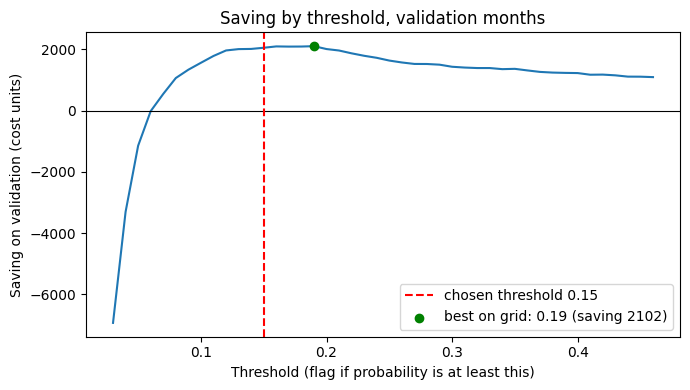

In [137]:
cost_late, cost_flag = 10, 2
yv = np.asarray(y_val_ff)

grid = np.arange(0.03, 0.46, 0.01)
savings = []
for th in grid:
    fl = y_val_pred >= th
    savings.append(yv[fl].sum() * cost_late - fl.sum() * cost_flag)
savings = np.array(savings)
best = grid[savings.argmax()]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grid, savings, color='#1f77b4')
ax.axhline(0, color='black', linewidth=0.8)
ax.axvline(0.15, color='red', linestyle='--', label='chosen threshold 0.15')
ax.scatter([best], [savings.max()], color='green', zorder=5,
           label=f'best on grid: {best:.2f} (saving {int(savings.max())})')
ax.set_xlabel('Threshold (flag if probability is at least this)')
ax.set_ylabel('Saving on validation (cost units)')
ax.set_title('Saving by threshold, validation months')
ax.legend()
plt.tight_layout()
fig.savefig('/content/figures/saving_vs_threshold.png', dpi=150, bbox_inches='tight')
plt.show()

## Final model and the test score

The tuned LightGBM is retrained on all training months (before 2018-03-01) with
the best settings. The threshold (0.15) was chosen on validation and is not
changed. The test months are scored once, here.
Caveat: retraining on more data shifts the probabilities slightly, so the
threshold may be a little off for the final model.

In [74]:
threshold = 0.15

lgb_final = LGBMClassifier(random_state=42, verbose=-1, subsample_freq=1, **best_params)
lgb_final.fit(x_search, y_search)

y_pred_test = lgb_final.predict_proba(x_test_ff)[:, 1]

print('PR-AUC :', average_precision_score(y_test, y_pred_test))
print('ROC-AUC :', roc_auc_score(y_test, y_pred_test))
print('Random guess :', y_test.mean())

PR-AUC : 0.3814016425429048
ROC-AUC : 0.8135846026267912
Random guess : 0.08795013850415513


### Business result on the test months

The threshold (0.15) was chosen on validation and is not changed. We apply it to
the test months and compute the saving with the same assumptions
(late = 10, flag = 2, intervention always works).

In [75]:
threshold = 0.15
cost_late = 10
cost_flag = 2

flagged = y_pred_test >= threshold
n_flagged = flagged.sum()
n_caught = y_test_ff.values[flagged].sum()
saving = n_caught * cost_late - n_flagged * cost_flag

print('Flagged:', n_flagged)
print('Truly late among flagged:', n_caught)
print('Precision:', n_caught / n_flagged)
print('Recall:', n_caught / y_test_ff.sum())
print('Saving:', saving)

Flagged: 2608
Truly late among flagged: 1091
Precision: 0.4183282208588957
Recall: 0.31816856226305046
Saving: 5694


### Precision-recall curve on the test months

Each curve shows what happens when we flag more and more parcels: moving right
catches more late parcels (recall) but a smaller share of the flagged ones are
really late (precision). The dashed line is random flagging. The red dot is the
operating point at threshold 0.15. A higher curve is better.

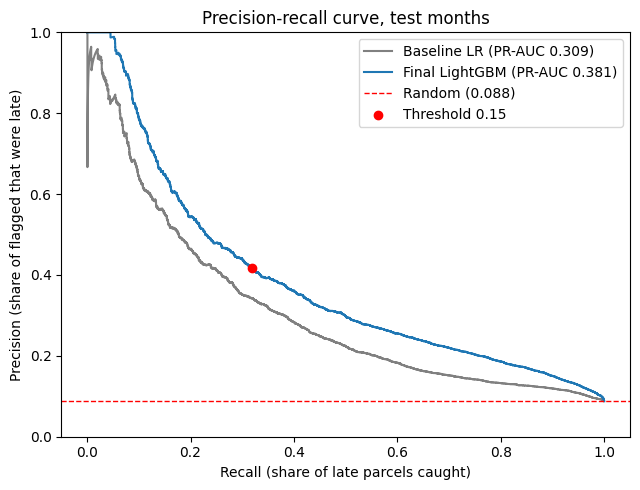

In [134]:
import os
import numpy as np
from sklearn.metrics import precision_recall_curve
os.makedirs('/content/figures', exist_ok=True)

y = np.asarray(y_test_ff)
p_b, r_b, _ = precision_recall_curve(y, y_pred)
p_f, r_f, _ = precision_recall_curve(y,y_pred_test)

fl = y_pred_test >= 0.15
op_prec = y[fl].mean()
op_rec = y[fl].sum() / y.sum()

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(r_b, p_b, color='grey', label=f'Baseline LR (PR-AUC {average_precision_score(y, y_pred):.3f})')
ax.plot(r_f, p_f, color='#1f77b4', label=f'Final LightGBM (PR-AUC {average_precision_score(y, y_pred_test):.3f})')
ax.axhline(y.mean(), color='red', linestyle='--', linewidth=1, label=f'Random ({y.mean():.3f})')
ax.scatter([op_rec], [op_prec], color='red', zorder=5, label='Threshold 0.15')
ax.set_xlabel('Recall (share of late parcels caught)')
ax.set_ylabel('Precision (share of flagged that were late)')
ax.set_title('Precision-recall curve, test months')
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
fig.savefig('/content/figures/pr_curve.png', dpi=150, bbox_inches='tight')
plt.show()

### Why do parcels get flagged? (SHAP)

SHAP shows how much each feature pushes a parcel's late risk up or down. We
compute it for the final LightGBM on a random sample of 5,000 test parcels.

SHAP shows what the model relies on, which is correlation, not proof
that a feature causes lateness.

In [76]:
!pip install shap -q
import shap

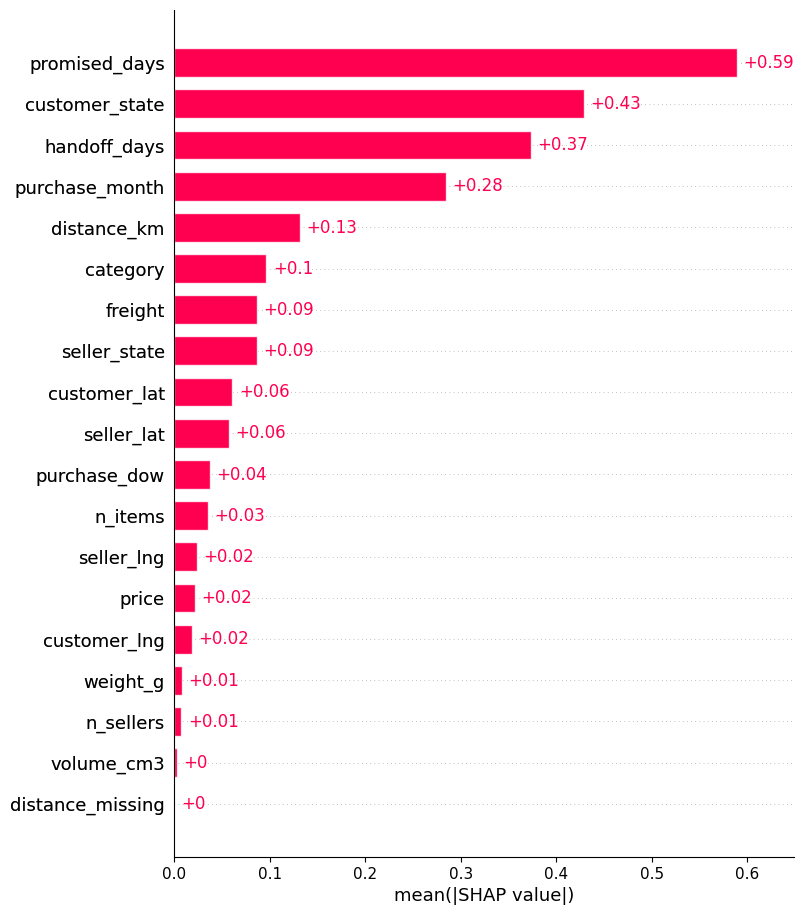

In [77]:
sample = x_test_ff.sample(5000, random_state=42)

explainer = shap.TreeExplainer(lgb_final)
shap_values = explainer(sample)

shap.plots.bar(shap_values, max_display=19)

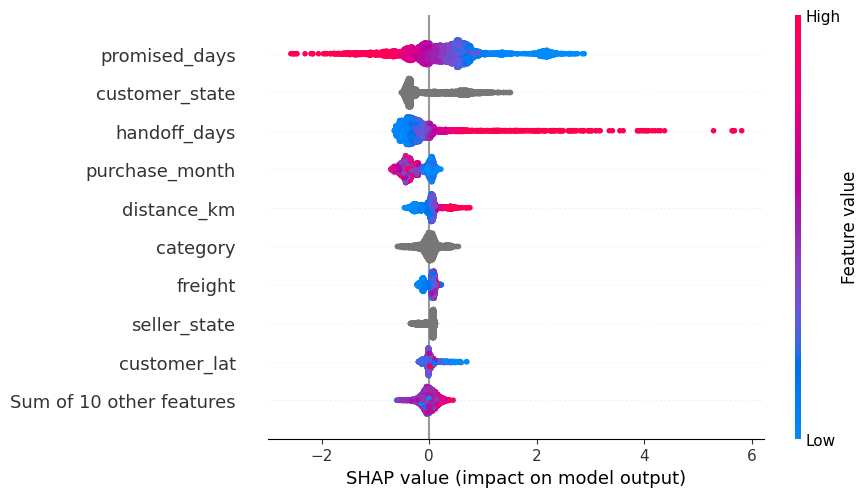

In [78]:
shap.plots.beeswarm(shap_values, max_display=10)

### Why was this one parcel flagged?

We take one parcel from the sample that the model flagged (probability at or
above 0.15) and show how each feature pushed its risk up or down.

In [79]:
sample_prob = lgb_final.predict_proba(sample)[:, 1]
flagged_idx = np.where(sample_prob >= 0.15)[0]

i = flagged_idx[0]
print('Late probability:', sample_prob[i])
sample.iloc[i]

Late probability: 0.19281742785936545


,82154
promised_days,20
handoff_days,0.908229
distance_km,1457.825419
weight_g,5450.0
freight,27.88
price,115.0
n_items,1
volume_cm3,12696.0
purchase_month,5
purchase_dow,2


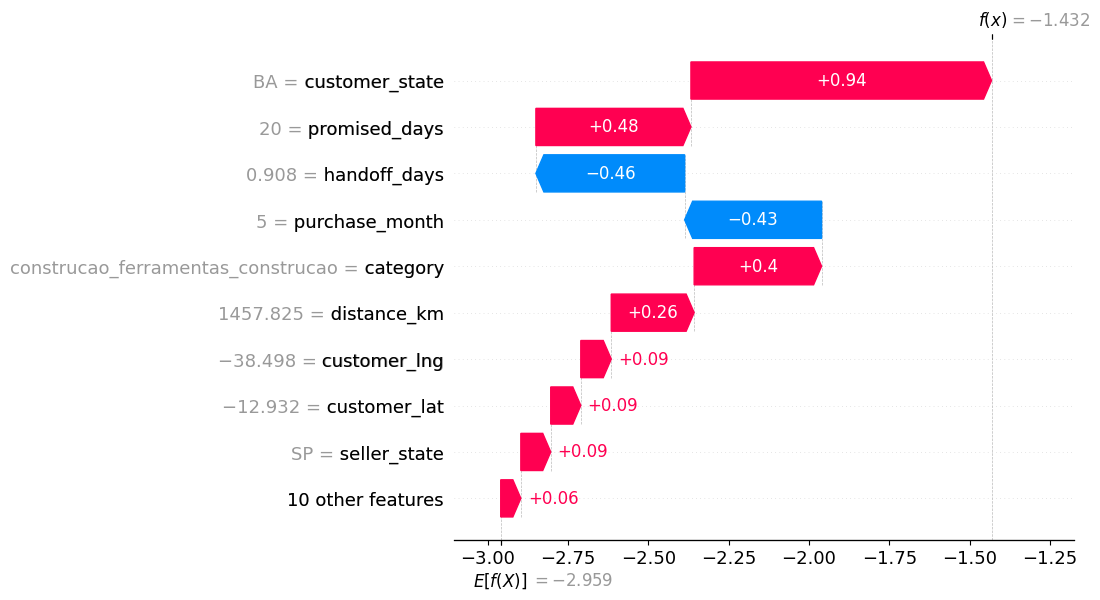

In [80]:
shap.plots.waterfall(shap_values[i])

### Model self explanation function

This function takes any parcel from the SHAP sample and prints its late
probability with the top reasons that raised and lowered the risk. The same
logic will be used in the prediction script.

In [81]:
def explain_parcel(idx, n_up=3, n_down=2):
    vals = shap_values[idx].values
    names = shap_values[idx].feature_names
    data = shap_values[idx].data
    order = np.argsort(vals)

    print('Late probability:', round(sample_prob[idx], 3))
    print('Raised the risk:')
    for k in order[::-1][:n_up]:
        if vals[k] > 0:
            print('  -', names[k], '=', data[k])
    print('Lowered the risk:')
    for k in order[:n_down]:
        if vals[k] < 0:
            print('  -', names[k], '=', data[k])

explain_parcel(flagged_idx[1])

Late probability: 0.158
Raised the risk:
  - customer_state = RJ
  - promised_days = 19
  - handoff_days = 5.1390162037037035
Lowered the risk:
  - purchase_month = 3
  - customer_lng = -43.107023598220486


### Error analysis: where does the model work worst?

For each segment of the test months we compare the real late rate, how many
parcels the model flagged, and how many of the late parcels it caught
(recall) and how many flagged were really late (precision). At Threshold 0.15.

In [82]:
res = test[['year_month', 'customer_state', 'category', 'is_late']].copy()
res['prob'] = y_pred_test
res['flagged'] = res['prob'] >= 0.15
res['caught'] = res['flagged'] & res['is_late']

def seg_report(col):
    g = res.groupby(col, observed=True).agg(
        orders=('is_late', 'size'),
        late=('is_late', 'sum'),
        flagged=('flagged', 'sum'),
        caught=('caught', 'sum'))
    g['late_rate'] = g['late'] / g['orders']
    g['precision'] = g['caught'] / g['flagged']
    g['recall'] = g['caught'] / g['late']
    return g.round(3)

seg_report('year_month')

,orders,late,flagged,caught,late_rate,precision,recall
year_month,,,,,,,
2018-03,7003,1496,647,355,0.214,0.549,0.237
2018-04,6791,361,336,108,0.053,0.321,0.299
2018-05,6719,556,262,101,0.083,0.385,0.182
2018-06,6050,82,59,17,0.014,0.288,0.207
2018-07,6119,274,469,143,0.045,0.305,0.522
2018-08,6306,660,835,367,0.105,0.440,0.556


### Error analysis by customer state


In [83]:
s = seg_report('customer_state')
s = s[s['orders'] >= 500]
s.sort_values('late_rate', ascending=False).head(10)

,orders,late,flagged,caught,late_rate,precision,recall
customer_state,,,,,,,
BA,1286,219,205,68,0.170,0.332,0.311
ES,747,127,40,22,0.170,0.550,0.173
PE,628,72,89,21,0.115,0.236,0.292
RJ,4594,528,258,130,0.115,0.504,0.246
GO,737,58,32,11,0.079,0.344,0.190
MG,4421,343,90,36,0.078,0.400,0.105
DF,885,68,45,18,0.077,0.400,0.265
SC,1309,98,106,34,0.075,0.321,0.347
SP,17670,1244,1200,544,0.070,0.453,0.437


### Error analysis by product category

In [84]:
c = seg_report('category')
c = c[c['orders'] >= 500]
c.sort_values('late_rate', ascending=False).head(10)

,orders,late,flagged,caught,late_rate,precision,recall
category,,,,,,,
beleza_saude,4103,448,369,190,0.109,0.515,0.424
telefonia,1433,139,110,48,0.097,0.436,0.345
eletronicos,1078,101,63,23,0.094,0.365,0.228
automotivo,1852,170,116,43,0.092,0.371,0.253
relogios_presentes,2770,250,185,60,0.090,0.324,0.240
ferramentas_jardim,1053,95,40,20,0.090,0.500,0.211
esporte_lazer,2794,251,178,70,0.090,0.393,0.279
cool_stuff,921,82,41,17,0.089,0.415,0.207
papelaria,853,76,49,23,0.089,0.469,0.303


### Risk tiers: what should operations do?

We group test parcels by predicted probability and check the real late rate in each
group. If higher predicted risk really means a higher late rate, the groups can be
turned into actions (for example: upgrade shipping for the highest tier, message
the customer for the middle tier).

In [85]:
res['tier'] = pd.cut(res['prob'], bins=[0, 0.15, 0.30, 0.50, 1.01],
                     labels=['low', 'medium', 'high', 'very high'], right=False)

t = res.groupby('tier', observed=True).agg(
    orders=('is_late', 'size'),
    late=('is_late', 'sum'))
t['late_rate'] = (t['late'] / t['orders']).round(3)
t

,orders,late,late_rate
tier,,,
low,36380,2338,0.064
medium,1904,620,0.326
high,357,175,0.490
very high,347,296,0.853


### How effective must each action be?

We do not know how often each action really works, because Olist has no data on
interventions. So we compute the break-even success rate per tier: the share of
the late-parcel loss (10) the action must remove for the action to pay for itself.

Break-even = action cost / (late rate x 10).

In [86]:
cost_late = 10

act = t.loc[['medium', 'high', 'very high']].copy()
act['action_cost'] = [1, 3, 5]
act['break_even_success'] = (act['action_cost'] / (act['late_rate'] * cost_late)).round(2)
act

,orders,late,late_rate,action_cost,break_even_success
tier,,,,,
medium,1904,620,0.326,1,0.31
high,357,175,0.490,3,0.61
very high,347,296,0.853,5,0.59


In [87]:
flat_break_even = (n_flagged * 2) / (n_caught * cost_late)
print('Flat policy break-even success rate:', round(flat_break_even, 3))

Flat policy break-even success rate: 0.478


## Saving the model

We save the final LightGBM with joblib, together with the feature list, the
threshold (0.15, chosen on validation) and the category labels. The prediction
script needs all of these to rebuild the inputs exactly as in training.

In [88]:
import joblib

joblib.dump(lgb_final, '/content/logistic_tracker.joblib')

meta = {
    'features': final_features,
    'threshold': 0.15,
    'categories': {c: list(x_search[c].cat.categories)
                   for c in ['category', 'seller_state', 'customer_state']}
}
joblib.dump(meta, '/content/model_meta.joblib')

['/content/model_meta.joblib']

## Prediction script

First we will create a small sample input file (10 parcels from the test months).

In the format the script expects: the 19 feature columns plus order_id.

Reading from CSV loses the column types, so the script has to rebuild them.

In [91]:
sample_in = test[['order_id'] + final_features].head(10)
sample_in.to_csv('/content/new_parcels.csv', index=False)

pd.read_csv('/content/new_parcels.csv').dtypes

,0
order_id,object
promised_days,int64
handoff_days,float64
distance_km,float64
weight_g,float64
freight,float64
price,float64
n_items,int64
volume_cm3,float64
purchase_month,int64


In [92]:
# Making predict.py

%%writefile predict.py
import sys
import argparse
import joblib
import pandas as pd

CAT_COLS = ['category', 'seller_state', 'customer_state']
OPTIONAL_EMPTY = ['seller_lat', 'seller_lng', 'customer_lat', 'customer_lng']

# allowed ranges (min, max) for numeric columns
RANGES = {
    'promised_days': (1, 200), 'handoff_days': (0, 150),
    'distance_km': (0, 4500), 'weight_g': (1, 500000),
    'freight': (0, 5000), 'price': (0, 50000),
    'n_items': (1, 100), 'volume_cm3': (1, 5000000),
    'purchase_month': (1, 12), 'purchase_dow': (0, 6),
    'n_sellers': (1, 20),
    'seller_lat': (-35, 6), 'seller_lng': (-75, -30),
    'customer_lat': (-35, 6), 'customer_lng': (-75, -30),
}


def fail(msg):
    print('ERROR:', msg)
    sys.exit(1)


def validate(df, features, categories):
    missing = [c for c in ['order_id'] + features if c not in df.columns]
    if missing:
        fail(f'missing columns: {missing}')

    for c in features:
        if c not in OPTIONAL_EMPTY and df[c].isnull().any():
            fail(f'column {c} has {df[c].isnull().sum()} empty values')

    for c, (lo, hi) in RANGES.items():
        if not pd.api.types.is_numeric_dtype(df[c]):
            fail(f'column {c} must be numeric')
        bad = df[c].notnull() & ((df[c] < lo) | (df[c] > hi))
        if bad.any():
            fail(f'column {c} has {bad.sum()} values outside {lo} to {hi} '
                 f'(first bad order_id: {df.loc[bad, "order_id"].iloc[0]})')

    if df['distance_missing'].dtype != bool:
        fail('column distance_missing must be True/False')

    for c in CAT_COLS:
        unknown = set(df[c].dropna()) - set(categories[c])
        if unknown:
            fail(f'column {c} has labels the model has never seen: {sorted(unknown)[:5]}')


def main():
    p = argparse.ArgumentParser()
    p.add_argument('--input', required=True)
    p.add_argument('--output', default='predictions.csv')
    p.add_argument('--model', default='lgb_final.joblib')
    p.add_argument('--meta', default='model_meta.joblib')
    a = p.parse_args()

    model = joblib.load(a.model)
    meta = joblib.load(a.meta)
    features = meta['features']

    df = pd.read_csv(a.input)
    if len(df) == 0:
        fail('input file has no rows')

    validate(df, features, meta['categories'])

    X = df[features].copy()
    for c in CAT_COLS:
        X[c] = pd.Categorical(X[c], categories=meta['categories'][c])

    out = df[['order_id']].copy()
    out['late_probability'] = model.predict_proba(X)[:, 1].round(4)
    out['flagged'] = out['late_probability'] >= meta['threshold']
    out.to_csv(a.output, index=False)
    print(f'OK: {len(out)} parcels scored, {out["flagged"].sum()} flagged '
          f'(threshold {meta["threshold"]}). Saved to {a.output}')


if __name__ == '__main__':
    main()

Writing predict.py


In [93]:
# Making script perform prediction on "new_parcels.csv"
!python predict.py --input new_parcels.csv --output predictions.csv --model logistic_tracker.joblib --meta model_meta.joblib

OK: 10 parcels scored, 1 flagged (threshold 0.15). Saved to predictions.csv


In [94]:
# Loading the predicted result
pd.read_csv('predictions.csv')

,order_id,late_probability,flagged
0,53cdb2fc8bc7dce0b6741e2150273451,0.1652,True
1,47770eb9100c2d0c44946d9cf07ec65d,0.0334,False
2,82566a660a982b15fb86e904c8d32918,0.0085,False
3,5ff96c15d0b717ac6ad1f3d77225a350,0.0547,False
4,432aaf21d85167c2c86ec9448c4e42cc,0.0363,False
5,dcb36b511fcac050b97cd5c05de84dc3,0.0317,False
6,f848643eec1d69395095eb3840d2051e,0.0205,False
7,f3e7c359154d965827355f39d6b1fdac,0.1166,False
8,acce194856392f074dbf9dada14d8d82,0.0290,False
9,dd78f560c270f1909639c11b925620ea,0.0321,False


### explain.py: risk tier, suggested action and reasons

Turns a late probability into a risk tier and a suggested action, and turns the
model's feature contributions into plain-language reasons.

In [113]:
%%writefile explain.py
import pandas as pd

# (lower bound, tier, suggested action)
TIERS = [
    (0.50, 'very high', 'Upgrade shipping'),
    (0.30, 'high', 'Priority handling or reroute'),
    (0.15, 'medium', 'Send the customer a proactive message'),
    (0.00, 'low', 'No action'),
]

REASONS = {
    'promised_days': lambda v: f'the promised delivery time ({v:.0f} days) leaves little room',
    'handoff_days': lambda v: f'the seller took {v:.1f} days to hand the parcel to the carrier',
    'distance_km': lambda v: f'the parcel has to travel {v:.0f} km',
    'weight_g': lambda v: f'the parcel is heavy ({v / 1000:.1f} kg)',
    'volume_cm3': lambda v: 'the parcel is bulky',
    'freight': lambda v: f'the shipping cost is high ({v:.0f})',
    'n_items': lambda v: f'the order has {v:.0f} items',
    'n_sellers': lambda v: f'the order has items from {v:.0f} sellers',
    'category': lambda v: f'products in the category "{v}" were often late',
    'customer_state': lambda v: f'the customer is in {v}, where parcels were often late',
    'seller_state': lambda v: f'the seller is in {v}, where parcels were often late',
    'purchase_month': lambda v: f'month {v:.0f} was often a late period in the history',
    'purchase_dow': lambda v: 'the day of the week of the order',
}


def tier_and_action(p):
    for low, name, action in TIERS:
        if p >= low:
            return name, action


def top_reasons(row, contrib, n=3):
    # row: one parcel (features), contrib: its feature contributions
    order = sorted(range(len(contrib)), key=lambda k: contrib[k], reverse=True)
    parts = []
    for k in order[:n]:
        if contrib[k] <= 0:
            break
        name, value = row.index[k], row.iloc[k]
        if pd.isnull(value):
            parts.append('the location of the parcel is unknown')
        elif name in REASONS:
            parts.append(REASONS[name](value))
        else:
            parts.append(f'{name} = {value}')
    return '; '.join(parts) if parts else 'no single strong reason'

Writing explain.py


In [116]:
import importlib
import explain
importlib.reload(explain)
from explain import tier_and_action, top_reasons

X10 = x_test_ff.head(10)
contrib = lgb_final.predict(X10, pred_contrib=True)[:, :-1]

for k in range(10):
    p = y_pred_test[k]
    tier, action = tier_and_action(p)
    print(round(p, 3), tier, '|', action)
    if p >= 0.15:
        print('Reasons:', top_reasons(X10.iloc[k], contrib[k]))

0.165 medium | Send the customer a proactive message
Reasons: the customer is in BA, where parcels were often late; the promised delivery time (19 days) leaves little room; the parcel has to travel 851 km
0.033 low | No action
0.008 low | No action
0.055 low | No action
0.036 low | No action
0.032 low | No action
0.021 low | No action
0.117 low | No action
0.029 low | No action
0.032 low | No action


### Adding reasons and suggested actions to predict.py

predict.py now also has outputs, for each parcel, a risk tier, a suggested action,
and (for flagged parcels) the top reasons from the model's feature contributions.

In [117]:
text = open('/content/predict.py').read()

old_import = "import joblib\n"
new_import = "import joblib\nfrom explain import tier_and_action, top_reasons\n"

old_block = """out = df[['order_id']].copy()
    out['late_probability'] = model.predict_proba(X)[:, 1].round(4)
    out['flagged'] = out['late_probability'] >= meta['threshold']"""


new_block = """prob = model.predict_proba(X)[:, 1]
    contrib = model.predict(X, pred_contrib=True)[:, :-1]
    out = df[['order_id']].copy()
    out['late_probability'] = prob.round(4)
    out['flagged'] = prob >= meta['threshold']
    out['risk_tier'] = [tier_and_action(p)[0] for p in prob]
    out['suggested_action'] = [tier_and_action(p)[1] for p in prob]
    out['reasons'] = [top_reasons(X.iloc[k], contrib[k]) if prob[k] >= meta['threshold'] else ''
                      for k in range(len(X))]
"""

assert old_import in text and old_block in text, 'patch text not found'
text = text.replace(old_import, new_import, 1).replace(old_block, new_block, 1)
open('/content/predict.py', 'w').write(text)
print('patched')

patched


In [118]:
!python predict.py --input new_parcels.csv --output predictions.csv --model logistic_tracker.joblib --meta model_meta.joblib

OK: 10 parcels scored, 1 flagged (threshold 0.15). Saved to predictions.csv


In [119]:
pd.set_option('display.max_colwidth', None)
pd.read_csv('predictions.csv')

,order_id,late_probability,flagged,risk_tier,suggested_action,reasons
0,53cdb2fc8bc7dce0b6741e2150273451,0.1652,True,medium,Send the customer a proactive message,"the customer is in BA, where parcels were often late; the promised delivery time (19 days) leaves little room; the parcel has to travel 851 km"
1,47770eb9100c2d0c44946d9cf07ec65d,0.0334,False,low,No action,NaN
2,82566a660a982b15fb86e904c8d32918,0.0085,False,low,No action,NaN
3,5ff96c15d0b717ac6ad1f3d77225a350,0.0547,False,low,No action,NaN
4,432aaf21d85167c2c86ec9448c4e42cc,0.0363,False,low,No action,NaN
5,dcb36b511fcac050b97cd5c05de84dc3,0.0317,False,low,No action,NaN
6,f848643eec1d69395095eb3840d2051e,0.0205,False,low,No action,NaN
7,f3e7c359154d965827355f39d6b1fdac,0.1166,False,low,No action,NaN
8,acce194856392f074dbf9dada14d8d82,0.0290,False,low,No action,NaN
9,dd78f560c270f1909639c11b925620ea,0.0321,False,low,No action,NaN


### Decay check (PSI)

PSI compares the distribution of a feature in new data against the training
data. We cut the training values into 10 equal-sized groups and check how the new
values spread across those groups.

PSI under 0.10 is stable,
0.10 to 0.25 means watch, over 0.25 means retrain.

In [120]:
%%writefile monitor.py
import numpy as np
import pandas as pd


def psi(reference, new, bins=10):
    reference = pd.Series(reference).dropna()
    new = pd.Series(new).dropna()

    edges = np.unique(np.quantile(reference, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf

    ref_pct = np.histogram(reference, bins=edges)[0] / len(reference)
    new_pct = np.histogram(new, bins=edges)[0] / len(new)

    ref_pct = np.clip(ref_pct, 1e-4, None)
    new_pct = np.clip(new_pct, 1e-4, None)

    return float(np.sum((new_pct - ref_pct) * np.log(new_pct / ref_pct)))


def psi_status(value):
    if value < 0.10:
        return 'stable'
    if value < 0.25:
        return 'watch'
    return 'retrain'

Writing monitor.py


In [122]:
import sys, importlib
sys.path.insert(0, '/content')
import monitor
importlib.reload(monitor)

num_features = ['promised_days', 'handoff_days', 'distance_km',
                'weight_g', 'freight', 'price', 'volume_cm3', 'n_items']

for f in num_features:
    v = monitor.psi(x_search[f], x_test_ff[f])
    print(f, round(v, 3), monitor.psi_status(v))

promised_days 0.275 retrain
handoff_days 0.102 watch
distance_km 0.018 stable
weight_g 0.023 stable
freight 0.282 retrain
price 0.01 stable
volume_cm3 0.015 stable
n_items 0.0 stable


In [124]:
cols = ['promised_days', 'freight', 'handoff_days']

pd.DataFrame({
    'train_median': x_search[cols].median(),
    'test_median': x_test_ff[cols].median(),
    'train_mean': x_search[cols].mean(),
    'test_mean': x_test_ff[cols].mean(),
}).round(2)

,train_median,test_median,train_mean,test_mean
promised_days,24.00,21.00,24.64,21.52
freight,16.54,18.34,21.94,24.02
handoff_days,2.51,1.93,3.52,2.82


### Tests

We test what would hurt most if it broke silently: the label definition, the
leakage rule (no column that is only known after delivery may be a feature) and
the risk tiers.

 Tests for input validation and output shape come next.


In [125]:
%%writefile labels.py
def make_label(delivered_date, estimated_date):
    return delivered_date > estimated_date

Writing labels.py


In [126]:
!mkdir -p tests

In [127]:
%%writefile tests/test_label_and_leakage.py
import joblib
import pandas as pd
from labels import make_label
from explain import tier_and_action

FORBIDDEN = ['order_delivered_customer_date', 'is_late', 'order_status',
             'order_id', 'customer_id', 'seller_id']


def test_label_late_and_on_time():
    est = pd.Series(pd.to_datetime(['2018-01-10', '2018-01-10']))
    got = pd.Series(pd.to_datetime(['2018-01-12', '2018-01-08']))
    assert list(make_label(got, est)) == [True, False]


def test_label_exactly_on_promise_is_not_late():
    est = pd.Series(pd.to_datetime(['2018-01-10 00:00:00']))
    assert not make_label(est, est).iloc[0]


def test_no_leaky_columns_in_features():
    features = joblib.load('model_meta.joblib')['features']
    leaked = [c for c in FORBIDDEN if c in features]
    assert leaked == []


def test_tier_boundaries():
    assert tier_and_action(0.149)[0] == 'low'
    assert tier_and_action(0.15)[0] == 'medium'
    assert tier_and_action(0.30)[0] == 'high'
    assert tier_and_action(0.50)[0] == 'very high'

Writing tests/test_label_and_leakage.py


In [128]:
%cd /content
!pip install pytest -q
!python -m pytest tests -q

/content
....                                                                     [100%]
4 passed in 0.64s


In [130]:
same_day = (delivered['order_delivered_customer_date'].dt.date ==
            delivered['order_estimated_delivery_date'].dt.date) & delivered['is_late']
print('Late parcels delivered on the promised day itself:', same_day.sum(), 'of', delivered['is_late'].sum())

Late parcels delivered on the promised day itself: 1291 of 7823


## Wrap-up

I built a model that predicts which parcels will arrive late, using only what is known when the carrier picks the parcel up. A time-based split kept the evaluation honest: train on early months, tune on validation, score the test months once.

- **Result:** on the test months the final LightGBM scored PR-AUC 0.384 against 0.309 for the logistic regression baseline (random guessing: 0.088). Flagging the riskiest 8% of parcels (threshold 0.15) caught about 1 in 3 late parcels.

- **Money (assumed costs):** under my assumed costs (late parcel 10, warning 2) the plan would have saved about 4,868 over the 6 test months. That figure assumes every warning works, and the plan breaks even only if warnings prevent at least 56% of the lateness.

- **Weak spots:** the model missed most of the March 2018 spike, some states (MG, RS, ES) have very low recall, and 68% of late parcels were rated "low risk".

The cost numbers and the actions per risk tier are my own assumptions, because Olist has no data on interventions. The reasons shown for each parcel are patterns the model learned, not proven causes. A short pilot on the medium-risk tier would be the first step toward a real rollout.